In [13]:
from dataretrieval import nwis
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
site = '09095500'

In [14]:
def plot_fig(data, x, y, xlabel, ylabel, title):
    plt.figure(figsize=(14, 5))
    plt.plot(
        data[x],
        data[y]
    )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [4]:
site_info = nwis.get_record(
    sites=site,
    service='site'
)

display(site_info)

C:\Users\katel\AppData\Local\Temp\ipykernel_23068\600482508.py:1: DeprecationWarning: `nwis.get_record` is deprecated and will be removed from `dataretrieval` on or after 2027-05-06; use the appropriate `waterdata.get_*()` for the service you need instead.
  site_info = nwis.get_record(


,agency_cd,site_no,station_nm,site_tp_cd,lat_va,long_va,dec_lat_va,dec_long_va,coord_meth_cd,coord_acy_cd,...,reliability_cd,gw_file_cd,nat_aqfr_cd,aqfr_cd,aqfr_type_cd,well_depth_va,hole_depth_va,depth_src_cd,project_no,geometry
0,USGS,09095500,"COLORADO RIVER NEAR CAMEO, CO.",ST,391421,1081556,39.239146,-108.266195,M,S,...,NaN,NYNNNNNN,NaN,NaN,NaN,NaN,NaN,NaN,858200110,POINT (-108.26619 39.23915)


In [5]:
flow = nwis.get_record(
    sites=site,
    service='dv',
    start='1990-01-01',
    end='2025-12-31',
    parameterCd='00060'
)

flow.head()

C:\Users\katel\AppData\Local\Temp\ipykernel_23068\3727217918.py:1: DeprecationWarning: `nwis.get_record` is deprecated and will be removed from `dataretrieval` on or after 2027-05-06; use the appropriate `waterdata.get_*()` for the service you need instead.
  flow = nwis.get_record(


,00060_Mean,00060_Mean_cd,site_no
datetime,,,
1990-01-01 00:00:00+00:00,1200,A,09095500
1990-01-02 00:00:00+00:00,1170,A,09095500
1990-01-03 00:00:00+00:00,1200,A,09095500
1990-01-04 00:00:00+00:00,1310,A,09095500
1990-01-05 00:00:00+00:00,1080,A,09095500


In [8]:
flow = pd.DataFrame(flow)

In [9]:
flow = flow.reset_index()

flow = flow.rename(columns={'datetime':'date', '00060_Mean': 'discharge_cfs'})
flow = flow[['date','discharge_cfs','site_no']]

In [10]:
flow['date'] = pd.to_datetime(flow['date']).dt.tz_localize(None)

In [11]:
flow_monthly = (flow
    .set_index('date')
    .resample('MS')['discharge_cfs']
    .mean()
    .reset_index()
)

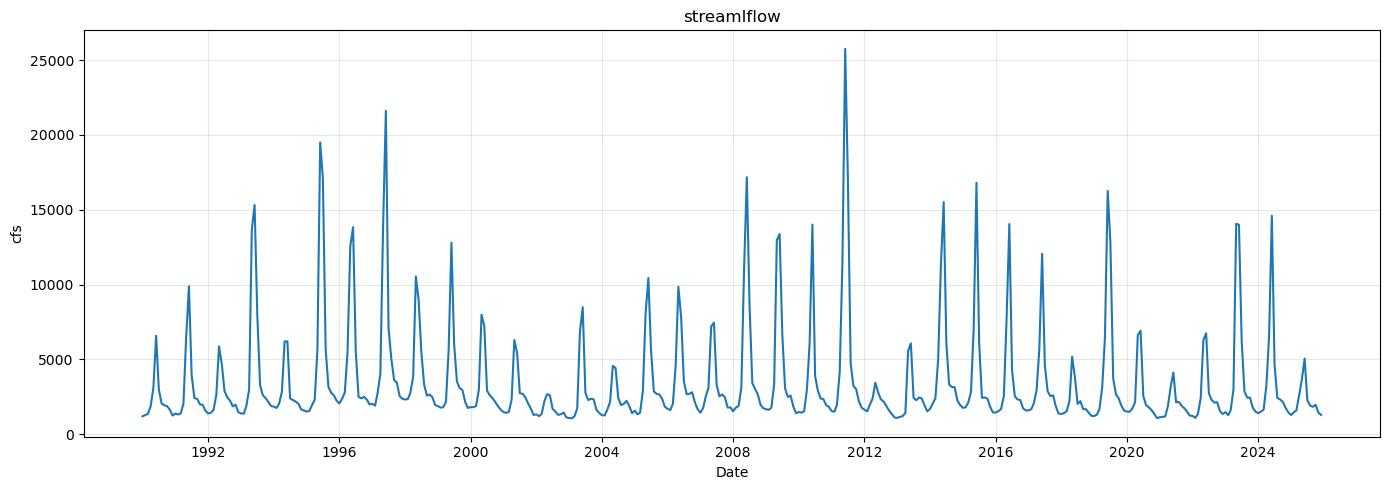

In [15]:
plot_fig(flow_monthly, 'date', 'discharge_cfs', 'Date', 'cfs', 'streamlflow')

In [16]:
# Daily dataset
flow.to_parquet(
    r"C:\Users\katel\extreme climate\data\streamflow_daily.parquet",
    index=False
)

# Monthly dataset
flow_monthly.to_parquet(
    r"C:\Users\katel\extreme climate\data\streamflow_monthly.parquet",
    index=False
)